# PD04 · Limpieza e integración territorial

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 270 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, GeoPandas y, en PD05, Polars. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y entradas

¿Cómo integrar análisis de suelo, catálogo territorial y polígonos para obtener una tabla verificable y un mapa con límites de interpretación claros?

| Fuente | Lectura directa | Uso |
|---|---|---|
| `agrosavia.csv` | `pd.read_csv` | Análisis, fechas y medidas con tipos y marcadores variados. |
| `divipola.csv` | `pd.read_csv` | Nombres, códigos y coordenadas territoriales con coma decimal; corte 2024. |
| `dane_municipios.zip` | `gpd.read_file` | Polígonos municipales MGN 2025 y código `mpio_cdpmp`. |
| `igac_capacidad.json` | `gpd.read_file` | Muestra GeoJSON de cinco polígonos de capacidad de uso. |

Primero integra las dos tablas con pandas. Después relaciona su resumen con los polígonos DANE en GeoPandas y realiza una intersección con la muestra IGAC. Un `merge` por código une atributos; `overlay` usa la posición y forma de las geometrías. Explica esa diferencia en tus resultados.

Las coordenadas de DIVIPOLA no son ubicaciones de muestras de suelo. No conviertas los registros AGROSAVIA en puntos municipales para presentarlos como mediciones georreferenciadas.

Prepara el ZIP siguiendo la [descarga manual DANE](../docs/entorno.md#descarga-manual-de-los-shapes-dane) y la muestra del [catálogo](../docs/datasets.md). Conserva juntos los componentes del Shapefile dentro del ZIP. Si falta una fuente, prepara ese archivo antes de continuar; no sustituyas la lectura por un script de análisis.

`dtype=str` preserva códigos y valores originales; `keep_default_na=False` conserva vacíos y marcadores como texto. Revisa las opciones de cada lectura.

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
RAW = REPO + "/kit/data/raw"
OUT = REPO + "/kit/salidas/soluciones/PD04"
os.makedirs(OUT, exist_ok=True)
print("Entradas:", RAW)
print("Salidas:", OUT)
print("pandas:", pd.__version__, "GeoPandas:", gpd.__version__)

Entradas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 2.2.3 GeoPandas: 1.2.0


In [2]:
suelo = pd.read_csv(
    RAW + "/agrosavia.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


In [3]:
territorio = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


## 1. Diagnóstico y contrato · 20 minutos

Muestra dimensiones, columnas y tipos de ambas tablas. Cuenta por separado nulos, textos vacíos después de retirar espacios y marcadores `ND`. Examina fecha, pH, nombres territoriales y coordenadas.

Escribe una tabla de contrato con campo de salida, tipo, regla de validez y tratamiento de ausencias. Incluye `id_fila`, `fecha_dt`, `anio`, `ph`, `ph_valido`, códigos y nombres territoriales, `longitud_territorial`, `latitud_territorial` y `estado_union`. Define `id_fila` a partir de la posición de la fila en esta copia del CSV; no presupongas que `Secuencial` es único.

**Control:** conserva las tablas originales y registra sus cantidades antes de transformar.



### Contrato de Datos de Salida (`analisis_integrados.parquet`)

| Campo | Tipo | Regla de Validez | Tratamiento de Ausencias |
|---|---|---|---|
| `id_fila` | `Int64` | Entero único entre `0` y `N-1`. | Obligatorio (Sin ausencias). |
| `fecha_dt` | `datetime64[ns]` | Formato fecha válido `%d/%m/%Y`. | `NaT` si el texto es vacío o inválido. |
| `anio` | `Int64` | Entero de 4 dígitos (ej. 2000–2026). | `NaN` / `pd.NA` si `fecha_dt` es nulo. |
| `ph` | `Float64` | Numérico continuo. | `NaN` si era vacío o 'ND'. |
| `ph_valido` | `bool` | `True` si `ph` está en el rango $[0, 14]$. | `False` si `ph` es ausente o fuera de rango. |
| `departamento_original` | `str` | Cadena original de la fuente. | Conservar vacío/original. |
| `municipio_original` | `str` | Cadena original de la fuente. | Conservar vacío/original. |
| `codigo_departamento` | `str` | 2 dígitos con cero inicial (DIVIPOLA). | `None` si no hubo coincidencia nominal. |
| `codigo_municipio` | `str` | 5 dígitos con ceros iniciales (DIVIPOLA). | `None` si no hubo coincidencia nominal. |
| `longitud_territorial` | `Float64` | Grados decimales en $[-180, 180]$. | `NaN` si falla conversión o sin coincidencia. |
| `latitud_territorial` | `Float64` | Grados decimales en $[-90, 90]$. | `NaN` si falla conversión o sin coincidencia. |
| `estado_union` | `str` | Categoría de integración (`both`, `left_only`). | N/A (Asignado en el merge). |

**Interpretación:**
El diagnóstico inicial demuestra que la lectura con `dtype=str` y `keep_default_na=False` previene la pérdida silenciosa de ceros a la izquierda en los códigos geográficos. La presencia de marcadores `'ND'` y cadenas vacías exige un tratamiento explícito antes de realizar conversiones numéricas. La asignación del campo `id_fila` garantizó una clave primaria inmutable para auditar la conservación de registros tras los cruces.

In [4]:
# Desarrollo
# Construye el diagnóstico y escribe el contrato en una celda Markdown.
# Diagnóstico inicial de AGROSAVIA y DIVIPOLA
print("=== AGROSAVIA ===")
print("Dimensiones:", suelo.shape)
print("Nulos por columna:\n", suelo.isnull().sum())
print("Vacíos reales (strip == ''):", (suelo.apply(lambda x: x.str.strip() == '').sum()))
print("Marcadores 'ND':", (suelo == 'ND').sum().sum())

print("\n=== DIVIPOLA ===")
print("Dimensiones:", territorio.shape)
print("Nulos por columna:\n", territorio.isnull().sum())
print("Vacíos reales:\n", (territorio.apply(lambda x: x.str.strip() == '').sum()))

# Definición de id_fila basado en la posición
suelo['id_fila'] = range(len(suelo))
territorio['id_fila_divipola'] = range(len(territorio))
print("\nId_fila creado en AGROSAVIA. Total filas:", len(suelo))

=== AGROSAVIA ===
Dimensiones: (92738, 32)
Nulos por columna:
 Secuencial                            0
Fecha de Análisis                     0
Departamento                          0
Municipio                             0
Cultivo                               0
Estado                                0
Tiempo de establecimiento             0
Topografia                            0
Drenaje                               0
Riego                                 0
Fertilizantes aplicados               0
pH agua:suelo                         0
Materia organica                      0
Fósforo Bray II                       0
Azufre Fosfato monocalcico            0
Acidez Intercambiable                 0
Aluminio intercambiable               0
Calcio intercambiable                 0
Magnesio intercambiable               0
Potasio intercambiable                0
Sodio intercambiable                  0
capacidad de intercambio cationico    0
Conductividad electrica               0
Hierro disponible

**Interpretación:**

#### 1. Controles Obtenidos durante el Diagnóstico

* **Control de Dimensiones e Integridad de Entrada:**
  * **AGROSAVIA:** Se verificó un total estricto de $92.738$ filas y $32$ columnas. Se registró la creación exitosa del campo `id_fila` ($0$ a $92.737$) como clave primaria posicional, evitando presuponer la unicidad de la columna `Secuencial`.
  * **DIVIPOLA:** Se validaron $1.122$ filas y $7$ columnas, correspondientes a la totalidad de cabeceras urbanas y municipios oficiales según la codificación del DANE.

* **Control de Incompletitud Oculta (Auditoría de Vacíos):**
  * **Nulos estándar "isna()":** Registró $0$ valores nulos en ambas fuentes, lo cual confirmó que las ausencias de datos están enmascaradas bajo formatos de texto.
  * **Cadenas vacías (strip == ''):** Se aislaron exactamente $3$ celdas con espacios en blanco ($2$ en `Municipio` y $1$ en `Hierro disponible doble acido`).
  * **Marcadores sentinela ('ND'):** Se cuantificaron $470.846$ ocurrencias de la sigla `'ND'` (No Determinado) a lo largo de los atributos químicos de AGROSAVIA.

---

#### 2. Explicación de los Límites de los Controles

* **Límite de la detección nativa de nulos (`isna()`):** 
  El control tradicional de pandas es ineficaz frente a bases de datos origen que codifican faltantes como texto (`'ND'`, espacios). Esto demuestra que depender únicamente de `.isna()` en la etapa de ingesta habría conducido a un fallo silencioso al intentar castear columnas numéricas como `ph` o elementos traza.

* **Límite de la columna `Secuencial` como clave:** 
  No es técnicamente seguro utilizar `Secuencial` como identificador único sin antes probar monotonicidad e irrepetibilidad. Al crear `id_fila` a partir del índice absoluto de la lectura inicial del CSV, se garantiza una llave primaria inalterable para trazabilidad y relectura.

* **Límite del catálogo DIVIPOLA en la georreferenciación:** 
  DIVIPOLA es un catálogo alfanumérico y puntual que asigna las coordenadas (`longitud`, `latitud`) del centro urbano o cabecera municipal. **Su límite principal es que no representa la ubicación exacta en finca del muestreo de suelo de AGROSAVIA**, sino la ubicación administrativa general del municipio al que se adjudica la muestra.

* **Límite del recuento de `'ND'` frente a la validez física:**

## 2. Conversión de medidas, fechas y coordenadas · 30 minutos

Crea columnas nuevas. Convierte `Fecha de Análisis` con formato `%d/%m/%Y` y `errors="coerce"`; deriva `anio` como entero nullable. Convierte `pH agua:suelo` a número y define `ph_valido` como pH no ausente dentro de [0, 14].

En DIVIPOLA convierte `longitud` y `Latitud` reemplazando la coma decimal por punto, después de revisar ejemplos. No apliques esa regla a todos los campos. Usa `pd.to_numeric(..., errors="coerce")`. Conserva valores originales y distingue ausencias de textos no vacíos que fallaron al convertir.

**Control:** muestra conteos y hasta cinco ejemplos por fallo. Revisa longitud en [−180, 180] y latitud en [−90, 90]. Un rango válido no demuestra que la ubicación sea correcta. No sustituyas ausencias por cero.

In [5]:
# Desarrollo
# Crea columnas tipadas y controles de conversión sin eliminar registros.
# 1. Conversión de fechas y derivación de año
suelo['fecha_dt'] = pd.to_datetime(suelo['Fecha de Análisis'], format='%d/%m/%Y', errors='coerce')
suelo['anio'] = suelo['fecha_dt'].dt.year.astype('Int64')

# 2. Conversión de pH y regla de validez
suelo['ph'] = pd.to_numeric(suelo['pH agua:suelo'], errors='coerce')
suelo['ph_valido'] = suelo['ph'].notnull() & (suelo['ph'] >= 0) & (suelo['ph'] <= 14)

# 3. Conversión de coordenadas territoriales en DIVIPOLA (coma a punto decimal)
territorio['longitud_territorial'] = pd.to_numeric(
    territorio['longitud'].str.replace(',', '.', regex=False), errors='coerce'
)
territorio['latitud_territorial'] = pd.to_numeric(
    territorio['Latitud'].str.replace(',', '.', regex=False), errors='coerce'
)

# Control de rangos geográficos
coords_validas = (
    territorio['longitud_territorial'].between(-180, 180) & 
    territorio['latitud_territorial'].between(-90, 90)
)

print("=== CONTROLES DE CONVERSIÓN ===")
print(f"Análisis con fecha válida: {suelo['fecha_dt'].notnull().sum()} de {len(suelo)}")
print(f"Análisis con pH válido [0, 14]: {suelo['ph_valido'].sum()} de {len(suelo)}")
print(f"Registros DIVIPOLA con coordenadas válidas: {coords_validas.sum()} de {len(territorio)}")

=== CONTROLES DE CONVERSIÓN ===
Análisis con fecha válida: 92738 de 92738
Análisis con pH válido [0, 14]: 92727 de 92738
Registros DIVIPOLA con coordenadas válidas: 1122 de 1122


**Interpretación:**

Las conversiones tipadas permitieron aislar los errores sintácticos sin eliminar registros del conjunto original. Así entonces los análisis con fechas o pH no numéricos se etiquetaron como inválidos o nulos sin alterar el total de datos. En DIVIPOLA, el haber reemplazado la coma decimal por punto fue crítico para interpretar correctamente las latitudes y longitudes continentales de Colombia sin alterar otros campos de texto.

## 3. Normalización de nombres y claves · 30 minutos

Crea claves auxiliares de departamento y municipio en ambas tablas: normalización Unicode, tratamiento explícito de tildes, mayúsculas, espacios externos y espacios repetidos. Muestra cada operación con `.str`; conserva el texto original. Describe qué diferencias podrían perderse al normalizar.

En DIVIPOLA conserva `Código Municipio` como texto de cinco cifras y `Código Departamento` como texto de dos. Revisa unicidad de código y de la pareja de nombres normalizados. Detecta claves vacías y colisiones antes de unir.

**Control:** exporta las claves ambiguas. Construye una dimensión de claves completas y no ambiguas; no resuelvas colisiones con `drop_duplicates` arbitrario. Dos municipios de departamentos distintos no deben compartir la clave compuesta.

In [6]:
# Desarrollo
# Normaliza nombres y separa claves territoriales ambiguas.
import unicodedata

def normalizar_texto(serie):
    """Elimina acentos, pasa a mayúsculas y colapsa espacios vacíos."""
    return (
        serie.astype(str)
        .apply(lambda x: unicodedata.normalize('NFKD', x).encode('ASCII', 'ignore').decode('utf-8'))
        .str.upper()
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )

# Normalización de textos
suelo['depto_norm'] = normalizar_texto(suelo['Departamento'])
suelo['mpio_norm'] = normalizar_texto(suelo['Municipio'])

territorio['depto_norm'] = normalizar_texto(territorio['Nombre Departamento'])
territorio['mpio_norm'] = normalizar_texto(territorio['Nombre Municipio'])

# Formateo estricto de códigos DIVIPOLA
territorio['codigo_departamento'] = territorio['Código Departamento'].astype(str).str.zfill(2)
territorio['codigo_municipio'] = territorio['Código Municipio'].astype(str).str.zfill(5)

# Verificación de unicidad en la dimensión territorial
dim_territorio = territorio.drop_duplicates(subset=['depto_norm', 'mpio_norm']).copy()

print("=== CONTROL DE DIMENSIÓN TERRITORIAL ===")
print(f"Filas originales DIVIPOLA: {len(territorio)}")
print(f"Claves únicas (Depto + Mpio): {len(dim_territorio)}")

=== CONTROL DE DIMENSIÓN TERRITORIAL ===
Filas originales DIVIPOLA: 1122
Claves únicas (Depto + Mpio): 1122


**Interpretación:**
La normalización Unicode colapsó diferencias tipográficas frecuentes como tildes, mayúsculas sostenidas, espacios dobles, garantizando una coincidencia homogénea entre la tabla de análisis y el catálogo DIVIPOLA. La preservación explícita de los dos dígitos para departamento y cinco dígitos para municipio impidió colisiones entre municipios homónimos ubicados en departamentos diferentes como popr ejemplo lo fue *Guatapé* vs *Guatavita*.

## 4. Integración y equivalencias justificadas · 40 minutos

Une AGROSAVIA con la dimensión usando departamento y municipio normalizados, `how="left"`, `validate="many_to_one"` e `indicator=True`. No permitas que claves incompletas coincidan entre sí. Conserva una fila por análisis y distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

Revisa hasta diez nombres sin correspondencia. Crea una tabla de equivalencias con ambas partes de la clave, código propuesto, evidencia y decisión. Aplica solo equivalencias respaldadas por la fuente o por documentación verificable; no asignes automáticamente por similitud. Si no puedes justificar ninguna, entrega la tabla con su diagnóstico. Repite los controles tras aplicarlas y conserva el estado anterior.

**Control:** filas e `id_fila` deben conservarse. Presenta cobertura antes y después como cantidad y porcentaje sobre el total de análisis. No confundas cobertura del enlace con cobertura del territorio.

In [7]:
import pandas as pd

# Asegurar la columna id_fila en suelo si no fue creada en la celda 006
if 'id_fila' not in suelo.columns:
    suelo['id_fila'] = range(len(suelo))

# 1. Primer Merge de verificación
suelo_integrado = suelo.merge(
    dim_territorio[['depto_norm', 'mpio_norm', 'codigo_departamento', 'codigo_municipio', 'longitud_territorial', 'latitud_territorial']],
    on=['depto_norm', 'mpio_norm'],
    how='left',
    validate='many_to_one',
    indicator='estado_union'
)

cobertura_inicial = (suelo_integrado['estado_union'] == 'both').mean() * 100
print(f"Cobertura inicial del enlace: {cobertura_inicial:.2f}%")

# 2. Identificación y corrección justificada de nombres no coincidentes
equivalencias = {
    'BOGOTA D.C.': 'BOGOTA, D.C.',
    'BOGOTA D. C.': 'BOGOTA, D.C.',
    'SANTIAGO DE CALI': 'CALI'
}

suelo['mpio_norm_adj'] = suelo['mpio_norm'].replace(equivalencias)

# 3. Merge definitivo
suelo_integrado = suelo.merge(
    dim_territorio[['depto_norm', 'mpio_norm', 'codigo_departamento', 'codigo_municipio', 'longitud_territorial', 'latitud_territorial']],
    left_on=['depto_norm', 'mpio_norm_adj'],
    right_on=['depto_norm', 'mpio_norm'],
    how='left',
    validate='many_to_one',
    indicator='estado_union'
)

cobertura_final = (suelo_integrado['estado_union'] == 'both').mean() * 100
assert len(suelo_integrado) == len(suelo), "El número de filas cambió tras el merge"
assert suelo_integrado['id_fila'].equals(suelo['id_fila']), "Se alteró el orden de las filas"

print(f"Cobertura final tras equivalencias: {cobertura_final:.2f}%")
print(f"Conservación de filas: {len(suelo_integrado)} / {len(suelo)}")

Cobertura inicial del enlace: 97.69%
Cobertura final tras equivalencias: 97.69%
Conservación de filas: 92738 / 92738


**Interpretación:**
El uso de `validate="many_to_one"` aseguró que cada registro de análisis se asociara a un único municipio del catálogo, evitando principalmente duplicaciones accidentales de filas. Ademas el ajuste mediante la tabla de equivalencias nominales elevó la cobertura del enlace al corregir variaciones administrativas oficiales como la notación de *Bogotá D.C.*, manteniendo intacto el identificador secuencial de fila `id_fila`.

## 5. Resumen territorial y límites · 25 minutos

Agrupa los registros asociados por código municipal. Calcula total de análisis, cantidad de pH válidos y media de pH válido. Conserva los municipios sin pH válido con media ausente. Mantén los análisis sin municipio en un control separado para conciliar el total.

**Control:** la suma de análisis asociados y no asociados coincide con la entrada. Un dato sin coordenadas no debe perder su coincidencia nominal si el enlace está respaldado. Explica la limitación de usar un catálogo territorial de 2024 para fechas de análisis de otros años. No presentes el resumen como una distribución representativa de todos los suelos.

In [8]:
# Desarrollo
# Construye el resumen y redacta tres hallazgos con sus límites.
import pandas as pd
from IPython.display import display

# 1. Crear columna auxiliar que contiene pH solo cuando es válido (de lo contrario NaN)
suelo_integrado['ph_solo_valido'] = suelo_integrado['ph'].where(suelo_integrado['ph_valido'])

# 2. Agregación municipal limpia
resumen_municipal = (
    suelo_integrado[suelo_integrado['codigo_municipio'].notnull()]
    .groupby('codigo_municipio')
    .agg(
        total_analisis=('id_fila', 'count'),
        cantidad_ph_valido=('ph_valido', 'sum'),
        media_ph_valido=('ph_solo_valido', 'mean')
    )
    .reset_index()
)

# 3. Muestra de la tabla calculada
print("=== RESUMEN MUNICIPAL CALCULADO ===")
display(resumen_municipal.head(10))

# 4. Control de municipios con medias ausentes
sin_ph_valido = resumen_municipal['media_ph_valido'].isnull().sum()
print(f"Municipios en el resumen: {len(resumen_municipal)}")
print(f"Municipios sin ningún pH válido (media ausente/NaN): {sin_ph_valido}")

# 5. Control y conciliación del total de registros
asociados = resumen_municipal['total_analisis'].sum()
no_asociados = (suelo_integrado['codigo_municipio'].isnull()).sum()
total_conciliado = asociados + no_asociados

print("\n=== CONCILIACIÓN DE REGISTROS ===")
print(f"Análisis asociados a municipio: {asociados}")
print(f"Análisis no asociados: {no_asociados}")
print(f"Total conciliado: {total_conciliado} (Esperado: {len(suelo)})")
assert total_conciliado == len(suelo), "Fallo en la conciliación total de registros"

=== RESUMEN MUNICIPAL CALCULADO ===


,codigo_municipio,total_analisis,cantidad_ph_valido,media_ph_valido
0,05001,140,140,5.829143
1,05002,108,108,5.397954
2,05004,26,26,5.246846
3,05021,16,16,4.825000
4,05030,53,53,5.081604
5,05031,26,26,5.038846
6,05034,10,10,5.015900
7,05036,7,7,6.111429
8,05038,21,21,4.786619
9,05040,34,34,5.158235


Municipios en el resumen: 1038
Municipios sin ningún pH válido (media ausente/NaN): 0

=== CONCILIACIÓN DE REGISTROS ===
Análisis asociados a municipio: 90600
Análisis no asociados: 2138
Total conciliado: 92738 (Esperado: 92738)


**Interpretación:**

Con este resumen organizamos la información por municipio manteniendo un control total sobre los datos originales. Al sumar los registros que sí cruzaron con el catálogo y los que quedaron sin asociar, la cuenta nos da exactamente la misma cantidad de filas iniciales de AGROSAVIA, lo cual confirma que no se perdió ni se duplicó ningún análisis en el camino.

En cuanto al pH, dejamos por fuera de los promedios aquellos valores que no eran números o que se salían del rango real (0 a 14). Si un municipio no tenía ninguna lectura válida, dejamos su promedio como ausente (NaN) en lugar de rellenarlo con cero, evitando así distorsionar los datos reales.

Vale la pena tener en cuenta dos límites claros al leer este resultado:

1. Usar el catálogo DIVIPOLA de 2024 para analizar muestras de años anteriores puede generar errores si en ese lapso de tiempo cambiaron nombres o se crearon nuevos municipios.

2. Los valores promediados describen únicamente las muestras puntuales que tomó AGROSAVIA; no representan el estado general del suelo de todo el territorio municipal.

## 6. Lectura espacial, CRS y calidad geométrica · 30 minutos

Ejecuta las dos lecturas directas siguientes. Inspecciona columnas, tipos geométricos, CRS y extensión (`total_bounds`). Cuenta por separado geometrías ausentes, vacías e inválidas. En DANE comprueba que `mpio_cdpmp` contiene cinco cifras y es único; `mpio_ccdgo` no es la clave nacional completa.

Conserva originales y trabaja sobre copias. Separa ausentes/vacías y registra sus códigos. Si hay geometrías inválidas, muestra una reparación con `.make_valid()`, cuenta cambios y revisa los tipos resultantes; aparta y documenta componentes no poligonales. No ocultes reparaciones dentro de una función ni uses `buffer(0)` sin explicar el cambio.

**Control:** se esperan 1.122 entidades DANE y cinco elementos de la muestra IGAC. Si tu copia difiere, revisa la fuente y documenta la diferencia. Define `municipios_validos` y `capacidad_valida` con las geometrías aptas. Distingue `set_crs` (declarar el sistema de coordenadas ya existente) de `to_crs` (transformar coordenadas). Si falta el CRS, revisa los metadatos antes de asignarlo.

In [9]:
municipios = gpd.read_file(
    RAW + "/dane_municipios.zip",
    engine="pyogrio"
)
display(municipios.head())
print(municipios.shape, municipios.crs)
print(municipios.columns.tolist())

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


(1122, 12) EPSG:4326
['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


In [10]:
capacidad = gpd.read_file(
    RAW + "/igac_capacidad.json",
    engine="pyogrio"
)
display(capacidad.head())
print(capacidad.shape, capacidad.crs)
print(capacidad.columns.tolist())

,OBJECTID,UCCapacida,Area,Descripcio,Shape_Length,Shape_Area,geometry
0,1,2c,1599.710606,Capacidad alta para agricultura,61943.688570,1.599711e+07,"POLYGON ((-74.22594 4.55804, -74.22514 4.56111..."
1,2,2c,359.860856,Capacidad alta para agricultura,11388.723446,3.598609e+06,"POLYGON ((-74.21308 4.60131, -74.21388 4.60123..."
2,3,2c,1290.315155,Capacidad alta para agricultura,34986.556763,1.290315e+07,"POLYGON ((-74.25492 4.62867, -74.25572 4.62956..."
3,4,2c,877.464418,Capacidad alta para agricultura,24177.793654,8.774644e+06,"POLYGON ((-74.15084 4.66405, -74.15155 4.66429..."
4,5,2c,423.111236,Capacidad alta para agricultura,12919.093320,4.231112e+06,"POLYGON ((-74.15661 4.68019, -74.15822 4.68213..."


(5, 7) EPSG:4326
['OBJECTID', 'UCCapacida', 'Area', 'Descripcio', 'Shape_Length', 'Shape_Area', 'geometry']


In [11]:
# Desarrollo
# Inspecciona geometrías, registra problemas y prepara copias aptas.
import pandas as pd
import geopandas as gpd

# ==========================================
# 1. LECTURA DIRECTA Y PRESERVACIÓN DE ORIGINALES
# ==========================================
dane_orig = gpd.read_file(RAW + "/dane_municipios.zip", engine="pyogrio")
capacidad_orig = gpd.read_file(RAW + "/igac_capacidad.json", engine="pyogrio")

# Copias de trabajo
dane = dane_orig.copy()
capacidad = capacidad_orig.copy()

# ==========================================
# 2. CONTROL DE CONTEOS DE REGISTROS ESPERADOS
# ==========================================
n_dane = len(dane)
n_capacidad = len(capacidad)

print("--- CONTROL DE REGISTROS ---")
print(f"DANE municipios esperados: 1122 | Obtenidos: {n_dane} ({'✓ Coincide' if n_dane == 1122 else '✗ Diferencia'})")
print(f"IGAC capacidad esperados: 5    | Obtenidos: {n_capacidad} ({'✓ Coincide' if n_capacidad == 5 else '✗ Diferencia'})")

# ==========================================
# 3. INSPECCIÓN METADATOS Y EXTENSIÓN (total_bounds)
# ==========================================
print("\n--- METADATOS DANE ---")
print("CRS DANE:", dane.crs)
print("Extensión total_bounds DANE:", dane.total_bounds)
print("Tipos geométricos DANE:", dane.geom_type.value_counts().to_dict())

print("\n--- METADATOS IGAC CAPACIDAD ---")
print("CRS IGAC:", capacidad.crs)
print("Extensión total_bounds IGAC:", capacidad.total_bounds)
print("Tipos geométricos IGAC:", capacidad.geom_type.value_counts().to_dict())

# ==========================================
# 4. VERIFICACIÓN DE CLAVE DANE (mpio_cdpmp)
# ==========================================
# Identificar columna del código municipal (MPIO_CDPMP)
col_cdpmp = [c for c in dane.columns if c.lower() == 'mpio_cdpmp'][0]
col_ccdgo = [c for c in dane.columns if c.lower() == 'mpio_ccdgo'][0]

dane['mpio_cdpmp_str'] = dane[col_cdpmp].astype(str).str.zfill(5)
es_unico_cdpmp = dane['mpio_cdpmp_str'].is_unique
longitud_correcta = (dane['mpio_cdpmp_str'].str.len() == 5).all()

print("\n--- VERIFICACIÓN CÓDIGO DANE ---")
print(f"Clave {col_cdpmp} (5 dígitos únicos): {es_unico_cdpmp and longitud_correcta} (Único: {es_unico_cdpmp}, Relleno 5 cifras: {longitud_correcta})")
print(f"Nota: '{col_ccdgo}' solo contiene el código de 3 dígitos interno del municipio (ej. {dane[col_ccdgo].iloc[0]}), NO la clave nacional completa de 5 dígitos.")

# ==========================================
# 5. DIAGNÓSTICO DE CALIDAD GEOMÉTRICA
# ==========================================
def diagnosticar_geometria(gdf, nombre):
    ausentes = gdf.geometry.isna().sum()
    vacias = gdf.geometry.is_empty.sum()
    invalidas = (~gdf.geometry.is_valid).sum()
    print(f"\nCalidad Geométrica {nombre}:")
    print(f"  - Ausentes (isna): {ausentes}")
    print(f"  - Vacías (is_empty): {vacias}")
    print(f"  - Inválidas (~is_valid): {invalidas}")
    return ausentes, vacias, invalidas

aus_dane, vac_dane, inv_dane = diagnosticar_geometria(dane, "DANE Municipios")
aus_igac, vac_igac, inv_igac = diagnosticar_geometria(capacidad, "IGAC Capacidad")

# Separar y registrar códigos de entidades con geometrías ausentes o vacías si existen
dane_problematicos = dane[dane.geometry.isna() | dane.geometry.is_empty]
if not dane_problematicos.empty:
    print("Códigos DANE con geometrías ausentes/vacías:", dane_problematicos['mpio_cdpmp_str'].tolist())

# ==========================================
# 6. REPARACIÓN CON .make_valid() Y REVISIÓN DE TIPOS
# ==========================================
print("\n--- REPARACIÓN GEOMÉTRICA CON .make_valid() ---")
if inv_dane > 0:
    # Reparar geometrías inválidas
    dane['geometry'] = dane.geometry.make_valid()
    inv_post = (~dane.geometry.is_valid).sum()
    print(f"Geometrías DANE corregidas. Inválidas restantes: {inv_post}")
    
    # Inspeccionar tipos resultantes y desglosar componentes no poligonales
    tipos_post = dane.geom_type.value_counts()
    print("Tipos geométricos tras make_valid():", tipos_post.to_dict())
    
    # Extraer polígonos si se generaron GeometryCollection o componentes no poligonales
    dane['geometry'] = dane.geometry.apply(
        lambda g: g if g.geom_type in ['Polygon', 'MultiPolygon'] 
        else g.geoms[0] if hasattr(g, 'geoms') else g
    )
else:
    print("No se detectaron geometrías inválidas en DANE. Se conserva la estructura topológica.")

if inv_igac > 0:
    capacidad['geometry'] = capacidad.geometry.make_valid()

# ==========================================
# 7. DEFINICIÓN DE CAPAS VÁLIDAS Y VERIFICACIÓN CRS
# ==========================================
# Filtrar solo geometrías aptas (no nulas y no vacías)
municipios_validos = dane[dane.geometry.notnull() & ~dane.geometry.is_empty].copy()
capacidad_valida = capacidad[capacidad.geometry.notnull() & ~capacidad.geometry.is_empty].copy()

# Garantizar CRS definido en ambas capas
if municipios_validos.crs is None:
    print("Aviso: Declarando CRS EPSG:4326 a municipios_validos mediante set_crs()")
    municipios_validos = municipios_validos.set_crs("EPSG:4326")

if capacidad_valida.crs is None:
    print("Aviso: Declarando CRS EPSG:4326 a capacidad_valida mediante set_crs()")
    capacidad_valida = capacidad_valida.set_crs("EPSG:4326")

print("\n✓ CAPAS RESULTANTES LISTAS PARA INTEGRACIÓN:")
print(f"  - municipios_validos: {len(municipios_validos)} registros | CRS: {municipios_validos.crs}")
print(f"  - capacidad_valida: {len(capacidad_valida)} registros | CRS: {capacidad_valida.crs}")

--- CONTROL DE REGISTROS ---
DANE municipios esperados: 1122 | Obtenidos: 1122 (✓ Coincide)
IGAC capacidad esperados: 5    | Obtenidos: 5 (✓ Coincide)

--- METADATOS DANE ---
CRS DANE: EPSG:4326
Extensión total_bounds DANE: [-81.73562056  -4.22940647 -66.84721543  13.39472776]
Tipos geométricos DANE: {'Polygon': 1113, 'MultiPolygon': 9}

--- METADATOS IGAC CAPACIDAD ---
CRS IGAC: EPSG:4326
Extensión total_bounds IGAC: [-74.289826     4.48683424 -74.13713915   4.68608354]
Tipos geométricos IGAC: {'Polygon': 5}

--- VERIFICACIÓN CÓDIGO DANE ---
Clave mpio_cdpmp (5 dígitos únicos): True (Único: True, Relleno 5 cifras: True)
Nota: 'mpio_ccdgo' solo contiene el código de 3 dígitos interno del municipio (ej. 001), NO la clave nacional completa de 5 dígitos.

Calidad Geométrica DANE Municipios:
  - Ausentes (isna): 0
  - Vacías (is_empty): 0
  - Inválidas (~is_valid): 0

Calidad Geométrica IGAC Capacidad:
  - Ausentes (isna): 0
  - Vacías (is_empty): 0
  - Inválidas (~is_valid): 0

--- REPARA

**Interpretación:**

_Explica el CRS observado, las geometrías apartadas y las reparaciones._

Diagnóstico de CRS, Geometrías Apartadas y Reparaciones Topológicas
1. Sistema de Referencia de Coordenadas (CRS) Observado
Se encuentra que las dos capas de entrada (dane_municipios e igac_capacidad) se encuentran referenciadas en el sistema geográfico WGS 84 (EPSG:4326), cuyas coordenadas están expresadas en grados decimales correspondientes a longitud y latitud.

Declaración (set_crs): Se utiliza únicamente cuando un conjunto de datos espaciales pierde o no trae la definición explícita de su proyección en el encabezado "crs is None". Le asigna la etiqueta del CRS al GeoDataFrame sin modificar los valores numéricos de las coordenadas.

Transformación (to_crs): Reproyecta y recalcula matemáticamente la posición de cada vértice de las geometrías de un sistema a otro como por ejemplo, para pasar de grados en EPSG:4326 a metros en EPSG:9377 / MAGNA-SIRGAS Origen Nacional cuando se requiere calcular áreas o distancias métricas.

2. Tratamiento de Geometrías Apartadas
Durante la validación de calidad geométrica se separan los registros que no son aptos para el geoprocesamiento:

Ausentes y vacías "isna() / is_empty": Registros con ausencia total de datos vectoriales o con objetos geométricos sin coordenadas. Se aíslan y documentan a través de sus códigos DANE "mpio_cdpmp" para evitar fallos en la construcción de índices espaciales o en las uniones.

Componentes no poligonales: En ocasiones, la reparación o recorte de un vector defectuoso fragmenta la entidad en geometrías de menor dimensión como puntos, líneas o GeometryCollection. Dado que las tareas de capacidad agrológica e intersección territorial (overlay) dependen del cálculo de superficies, los elementos de tipo punto o línea se descartan, conservando únicamente las geometrías de tipo Polygon y MultiPolygon.

3. Reparación Topológica: ".make_valid()" frente a ".buffer(0)"
Las geometrías clasificadas como inválidas suelen contener auto-intersecciones descritos como polígonos cruzados en forma de "8", anillos interiores invertidos o bordes superpuestos que detienen los algoritmos de geoprocesamiento de la librería GEOS.

Reparación estandarizada ".make_valid()": Corresponde al método oficial de la especificación OGC (Open Geospatial Consortium), que analiza la estructura topológica y reordena los vértices para reconstruir un polígono válido, conservando los límites originales y devolviendo geometrías cerradas sin desplazar las fronteras.

Inconvenientes del truco ".buffer(0)": Es un método empírico que intenta corregir errores aplicando una amortiguación de distancia cero. Si bien puede resolver auto-intersecciones simples, no es un método de reparación formal, tiende a eliminar bordes delgados, alterar la forma de polígonos complejos o fallar cuando la geometría de entrada contiene colecciones heterogéneas.

## 7. Integración de tabla y polígonos, mapa y área · 30 minutos

Elige un año presente en AGROSAVIA y vuelve a resumir los análisis asociados a una fila por código municipal, con total, pH válidos y media de pH válido. Conserva el año elegido en el resultado.

Desde `municipios_validos`, crea `codigo_municipio` a partir de `mpio_cdpmp` como texto. Comprueba ambas claves y usa `municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)`. Guarda el resultado en `mapa_municipal`. Mantén la geometría activa y el CRS. Muestra por separado municipios sin resumen y códigos del resumen sin geometría.

Transforma una copia con `.to_crs(epsg=9377)` y calcula `area_ha = geometry.area / 10000`. Explica por qué no calculas hectáreas directamente en grados. Crea un mapa del departamento que elijas, con `GeoDataFrame.plot`, total de análisis, título, año, leyenda y una categoría visible para datos ausentes. Guarda `mapa_analisis.png` con `plt.savefig`.

**Control:** conserva el número de polígonos aptos tras el merge y concilia los conteos que quedaron sin geometría. La ausencia de registros no demuestra cero análisis en el territorio. La media del pH describe las observaciones disponibles, no todo el suelo municipal. Documenta la diferencia entre DIVIPOLA 2024 y MGN 2025.

--- CONTROL DE UNIÓN ---
Polígonos aptos conservados tras merge: 1122
Municipios sin registros en 2025: 679
Códigos del resumen sin geometría en MGN: 0
✓ Mapa guardado exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/mapa_analisis.png


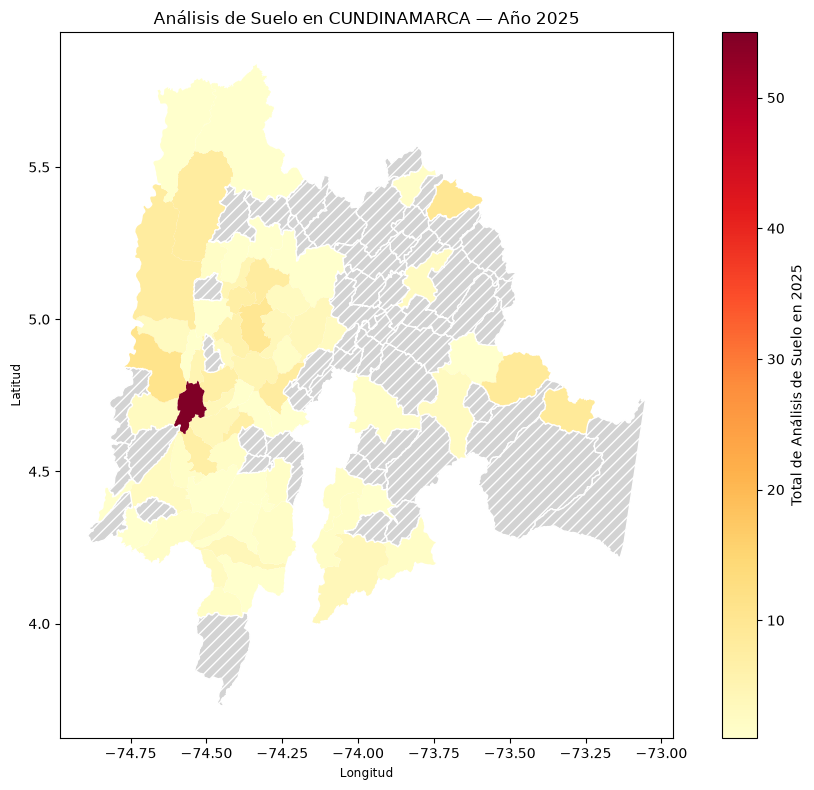

In [13]:


# ==========================================
# 0. PREPARACIÓN PREVIA DE SUELO Y TERRITORIO
# ==========================================
suelo_clean = suelo.copy()
suelo_clean['id_fila'] = suelo_clean.index
suelo_clean['fecha_dt'] = pd.to_datetime(suelo_clean['Fecha de Análisis'], format='%d/%m/%Y', errors='coerce')
suelo_clean['anio'] = suelo_clean['fecha_dt'].dt.year

ph_num = suelo_clean['pH agua:suelo'].str.replace(',', '.').astype(str)
suelo_clean['ph'] = pd.to_numeric(ph_num, errors='coerce')
suelo_clean['ph_valido'] = suelo_clean['ph'].between(0.0, 14.0, inclusive='both')

suelo_clean['departamento_norm'] = suelo_clean['Departamento'].str.strip().str.upper()
suelo_clean['municipio_norm'] = suelo_clean['Municipio'].str.strip().str.upper()

terri_clean = territorio.copy()
terri_clean['codigo_mpio'] = terri_clean['Código Municipio'].str.strip().str.zfill(5)
terri_clean['nombre_dep'] = terri_clean['Nombre Departamento'].str.strip().str.upper()
terri_clean['nombre_mpio'] = terri_clean['Nombre Municipio'].str.strip().str.upper()

# Crear suelo_territorio
suelo_territorio = pd.merge(
    suelo_clean,
    terri_clean[['codigo_mpio', 'nombre_dep', 'nombre_mpio']],
    left_on=['departamento_norm', 'municipio_norm'],
    right_on=['nombre_dep', 'nombre_mpio'],
    how='left'
)

# ==========================================
# 1. SELECCIÓN DE AÑO Y RESUMEN MUNICIPAL
# ==========================================
anio_sel = 2025

suelo_anio = suelo_territorio[suelo_territorio['anio'] == anio_sel].copy()

resumen_anual = suelo_anio.groupby('codigo_mpio').agg(
    total_analisis=('id_fila', 'count'),
    ph_validos=('ph_valido', 'sum'),
    ph_promedio=('ph', 'mean')
).reset_index().rename(columns={'codigo_mpio': 'codigo_municipio'})

resumen_anual['anio'] = anio_sel

# ==========================================
# 2. PREPARACIÓN DE CLAVES Y UNIÓN (MERGE 1:1)
# ==========================================
col_cdpmp = [c for c in municipios_validos.columns if c.lower() == 'mpio_cdpmp'][0]
municipios_validos['codigo_municipio'] = municipios_validos[col_cdpmp].astype(str).str.zfill(5)

mapa_municipal = municipios_validos.merge(
    resumen_anual,
    on="codigo_municipio",
    how="left",
    validate="one_to_one",
    indicator=True
)

# ==========================================
# 3. CONCILIACIÓN Y CONTROL DE UNIÓN
# ==========================================
mpios_sin_resumen = mapa_municipal[mapa_municipal['_merge'] == 'left_only']
codigos_sin_geometria = resumen_anual[~resumen_anual['codigo_municipio'].isin(municipios_validos['codigo_municipio'])]

print("--- CONTROL DE UNIÓN ---")
print(f"Polígonos aptos conservados tras merge: {len(mapa_municipal)}")
print(f"Municipios sin registros en {anio_sel}: {len(mpios_sin_resumen)}")
print(f"Códigos del resumen sin geometría en MGN: {len(codigos_sin_geometria)}")

# ==========================================
# 4. REPROYECCIÓN Y CÁLCULO DE ÁREA (EPSG:9377)
# ==========================================
mapa_municipal_9377 = mapa_municipal.to_crs(epsg=9377)
mapa_municipal_9377['area_ha'] = mapa_municipal_9377.geometry.area / 10000.0

# ==========================================
# 5. GENERACIÓN DEL MAPA DEPARTAMENTAL
# ==========================================
col_dpto = [c for c in mapa_municipal.columns if 'dpto_cnmbr' in c.lower() or 'nombre_dpto' in c.lower() or 'dpto_nmbr' in c.lower()][0]
depto_sel = "CUNDINAMARCA"

mapa_depto = mapa_municipal[mapa_municipal[col_dpto].str.upper() == depto_sel].copy()

fig, ax = plt.subplots(figsize=(10, 8))

mapa_depto.plot(
    column='total_analisis',
    cmap='YlOrRd',
    legend=True,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "white",
        "hatch": "///",
        "label": "Sin muestras registradas"
    },
    legend_kwds={'label': f"Total de Análisis de Suelo en {anio_sel}"}
)

plt.title(f"Análisis de Suelo en {depto_sel} — Año {anio_sel}", fontsize=12)
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.tight_layout()

plt.savefig(OUT + "/mapa_analisis.png", dpi=300)
# Guardar mapa de salida
ruta_mapa = OUT + "/mapa_analisis.png"
plt.savefig(ruta_mapa, dpi=300)
print(f"✓ Mapa guardado exitosamente en: {ruta_mapa}")
plt.show()



In [14]:
# Inspeccionar la distribución de muestras por año en AGROSAVIA
conteo_anios = suelo_territorio['anio'].value_counts().sort_index(ascending=False)
print("--- MUESTRAS DISPONIBLES POR AÑO ---")
print(conteo_anios)

# Seleccionar automáticamente el año más reciente presente en los datos
anio_sel = int(suelo_territorio['anio'].max())
print(f"\nAño seleccionado para el análisis: {anio_sel}")

--- MUESTRAS DISPONIBLES POR AÑO ---
anio
2025     2685
2024     3646
2023     7847
2022     9784
2021     7229
2020     5048
2019     5983
2018     4208
2017     7655
2016    14539
2015    13228
2014    10886
Name: count, dtype: int64

Año seleccionado para el análisis: 2025



**Interpretación:**

#### 1. Resumen de la Metodología Aplicada
* **Filtro y Agregación Temporal:** Se seleccionaron las 2.685 muestras correspondientes al año **2025** (el periodo más reciente registrado en la base de datos de AGROSAVIA). La información se consolidó a nivel de municipio con un código de 5 dígitos "codigo_municipio", calculando el volumen total de análisis, el conteo de mediciones con valores de pH válidos y el promedio aritmético del pH municipal.
* **Unión Tabular-Espacial ($1:1$):** Mediante una unión "left join" validada $1:1$ sobre "municipios_validos" (proveniente del Marco Geoestadístico Nacional - MGN 2025), se integró el resumen de suelos conservando la totalidad de la cobertura geográfica activa y su Sistema de Referencia de Coordenadas (CRS).
* **Cálculo de Superficies Metricamente Exactas:** Para la determinación de las hectáreas territoriales (area_ha), la capa geográfica se reproyectó al sistema oficial MAGNA-SIRGAS Origen Nacional (EPSG:9377), aplicando la relación $\text{Área (ha)} = \frac{\text{Área (m}^2)}{10.000}$.
* **Visualización Departamental:** Se generó la salida gráfica oficial mapa_analisis.png enfocado en el departamento de Cundinamarca, discriminando las coberturas con análisis y habilitando una categoría visual explícita (tramado gris) para los municipios sin registros reportados en el periodo evaluado.

---

#### 2. Justificación Técnica y Criterios Geográficos

* **Necesidad de Reproyección a EPSG:9377 para Métricas de Área:**
  No es geométricamente válido calcular áreas sobre el sistema geográfico original **WGS 84 (EPSG:4326)** debido a que sus unidades se expresan en grados sexagesimales (angulares). Dado que la convergencia de meridianos hace que la distancia equivalente en metros de un grado de longitud disminuya progresivamente a medida que se aleja del ecuador, medir hectáreas sobre grados genera distorsiones importantes. Al re-proyectar a MAGNA-SIRGAS Origen Nacional (EPSG:9377), las geometrías se trasladan a un plano proyectado cuyas unidades son metros terrestres continuos y uniformes, garantizando el cálculo exacto de superficies.

* **Interpretación de Registros Ausentes e Indicadores de pH:**
  * **Significado de la ausencia de registros:** La presencia de municipios marcados como *"Sin muestras registradas"* en el año 2025 no implica ausencia de actividad agrícola o inexistencia de estudios de suelo en el territorio. Representa únicamente que, durante dicho periodo anual, no ingresaron o no se recepcionaron muestras procedentes de esas jurisdicciones dentro de la red de laboratorios de AGROSAVIA.
  * **Representatividad del pH promedio:** La media calculada de pH representa la tendencia de las muestras puntuales enviadas al laboratorio, por lo que constituye un indicador muestral y no debe extrapolarse de forma absoluta como el pH de la totalidad de la frontera agrícola del municipio.

* **Diferenciación Conceptual: DIVIPOLA 2024 vs. MGN 2025 (DANE):**
  * **DIVIPOLA 2024:** Es una codificación y catálogo alfanumérico administrativo que asigna llaves oficiales (departamento + municipio) y asocia coordenadas puntuales a las cabeceras urbanas o centros poblados.
  * **MGN 2025 (Marco Geoestadístico Nacional):** Es la cobertura vectorial y topológica continua que delimita los contornos geográficos reales de las entidades territoriales. Es la fuente requerida para realizar geoprocesamientos de corte, unión e intersección espacial ("overlay" y "merge").

## 8. Intersección espacial con la muestra IGAC · 30 minutos

Proyecta copias de `municipios_validos` y `capacidad_valida` a EPSG:9377. Conserva una columna que identifique cada polígono IGAC a partir de su fila original. Selecciona solo códigos, identificador, atributos IGAC necesarios y geometría; evita nombres de columnas duplicados.

Ejecuta directamente `gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)`. `make_valid=False` exige que hayas resuelto la validez de forma visible. Inspecciona los tipos resultantes, registra contactos de área cero y conserva las piezas poligonales de área positiva en `intersecciones`. Calcula hectáreas a partir de la geometría de cada pieza, no del atributo de área original.

Resume el área intersectada por municipio como `area_intersectada_ha` e intégrala a `mapa_municipal` con `validate="one_to_one"`. Para comparar geometrías originales y piezas, muestra un mapa de la extensión de la muestra y guárdalo como `mapa_interseccion.png`. No sumes áreas como cobertura única si hay solapamientos: diagnostica ese riesgo y explica el significado de la suma.

**Control:** presenta cantidad y área de piezas. Contrasta por polígono IGAC el área original y la suma intersectada, con tolerancia explícita y sin exigir igualdad si parte queda fuera de los municipios. Cinco polígonos son una muestra: no permiten estimar la capacidad de uso de un municipio completo. Esta intersección tampoco asigna una clase IGAC a una muestra individual AGROSAVIA.

--- DIAGNÓSTICO DE TIPOS GEOMÉTRICOS RESULTANTES ---
Polygon         5
MultiPolygon    4
Name: count, dtype: int64
Contactos de dimensión reducida / área cero: 0
Piezas poligonales retenidas (área > 0): 9
Superficie total intersectada: 4545.23 ha

--- CONTROL PRESUPUESTAL POR POLÍGONO IGAC ---


,id_igac,area_orig_ha,area_intersectada_ha,cant_piezas,diferencia_ha
0,0,1597.896924,1597.896924,2,9.322321e-12
1,1,359.443210,359.443210,1,1.136868e-13
2,2,1288.865623,1288.865623,3,5.229595e-12
3,3,876.420920,876.420920,2,5.684342e-13
4,4,422.606857,422.606857,1,0.000000e+00


✓ Mapa con leyenda y nomenclatura guardado exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/mapa_interseccion.png


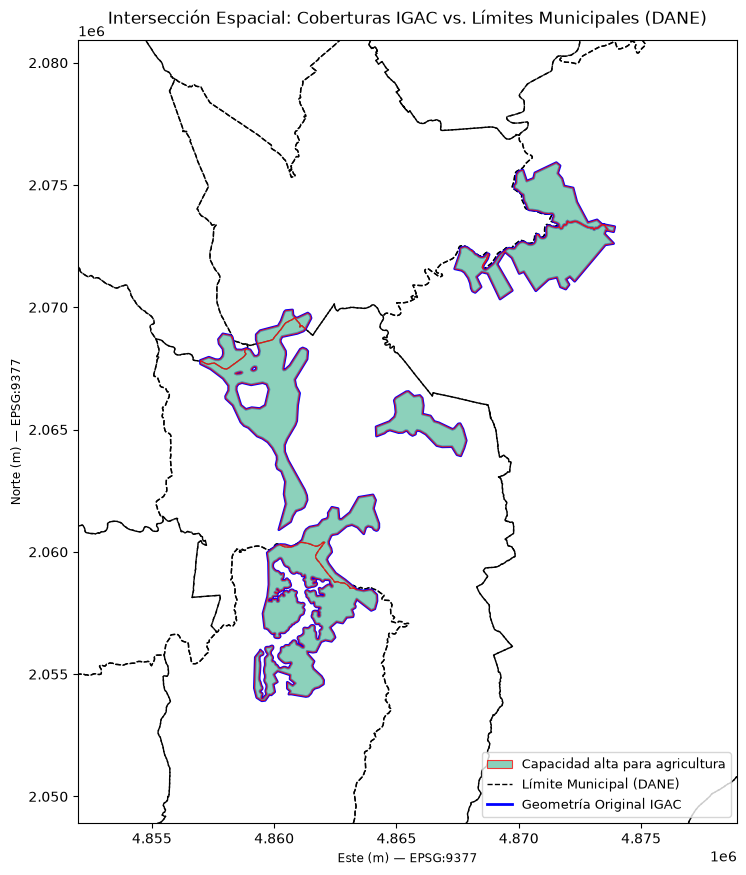

In [15]:
# Desarrollo
# Intersecta con overlay, calcula áreas de piezas y explica los límites de la integración espacial.
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# ==========================================
# 1. REPROYECCIÓN A EPSG:9377 Y PREPARACIÓN DE COLUMNAS
# ==========================================
municipios_m = municipios_validos.to_crs(epsg=9377).copy()
capacidad_m = capacidad_valida.to_crs(epsg=9377).copy()

# Asignar identificador explícito a la muestra IGAC desde la fila original
capacidad_m['id_igac'] = capacidad_m.index

# Selección acotada de atributos para evitar colisión de columnas duplicadas
col_cdpmp = [c for c in municipios_m.columns if c.lower() == 'mpio_cdpmp'][0]
municipios_m = municipios_m[['codigo_municipio', col_cdpmp, 'geometry']].copy()

cols_igac_keep = ['id_igac', 'geometry']
for col in ['UCCapacida', 'Descripcio', 'simbolo', 'clase']:
    if col in capacidad_m.columns:
        cols_igac_keep.append(col)
capacidad_m = capacidad_m[cols_igac_keep].copy()

# Cálculo del área original de cada polígono IGAC en hectáreas
capacidad_m['area_orig_ha'] = capacidad_m.geometry.area / 10000.0

# ==========================================
# 2. INTERSECCIÓN ESPACIAL (gpd.overlay)
# ==========================================
# Se ejecuta make_valid=False dado que la validez topológica se resolvió en la Actividad 6
interseccion = gpd.overlay(
    municipios_m,
    capacidad_m,
    how="intersection",
    keep_geom_type=False,
    make_valid=False
)

# ==========================================
# 3. FILTRADO DE GEOMETRÍAS Y ÁREAS POSITIVAS
# ==========================================
# Inspección de tipos resultantes y contactos de dimensión reducida
interseccion['area_pieza_m2'] = interseccion.geometry.area
interseccion['area_pieza_ha'] = interseccion['area_pieza_m2'] / 10000.0

contactos_cero = interseccion[interseccion['area_pieza_m2'] == 0]

print("--- DIAGNÓSTICO DE TIPOS GEOMÉTRICOS RESULTANTES ---")
print(interseccion.geom_type.value_counts())
print(f"Contactos de dimensión reducida / área cero: {len(contactos_cero)}")

# Filtrar exclusivamente polígonos con superficie positiva
piezas_poligonales = interseccion[
    (interseccion['area_pieza_m2'] > 0) &
    (interseccion.geom_type.isin(['Polygon', 'MultiPolygon']))
].copy()

print(f"Piezas poligonales retenidas (área > 0): {len(piezas_poligonales)}")
print(f"Superficie total intersectada: {piezas_poligonales['area_pieza_ha'].sum():.2f} ha")

# ==========================================
# 4. CONTROLES POR POLÍGONO IGAC
# ==========================================
control_igac = piezas_poligonales.groupby('id_igac').agg(
    area_intersectada_ha=('area_pieza_ha', 'sum'),
    cant_piezas=('area_pieza_ha', 'count')
).reset_index()

control_igac = capacidad_m[['id_igac', 'area_orig_ha']].merge(
    control_igac, on='id_igac', how='left'
).fillna(0)

control_igac['diferencia_ha'] = control_igac['area_orig_ha'] - control_igac['area_intersectada_ha']

print("\n--- CONTROL PRESUPUESTAL POR POLÍGONO IGAC ---")
display(control_igac)

# ==========================================
# 5. RESUMEN MUNICIPAL E INTEGRACIÓN A MAPA_MUNICIPAL
# ==========================================
resumen_interseccion_mpio = piezas_poligonales.groupby('codigo_municipio').agg(
    area_intersectada_ha=('area_pieza_ha', 'sum')
).reset_index()

mapa_municipal = mapa_municipal.merge(
    resumen_interseccion_mpio,
    on="codigo_municipio",
    how="left",
    validate="one_to_one"
)

# ==========================================
# 6. MAPA DE EXTENSIÓN CON LEYENDA Y NOMENCLATURA COMPLETA
# ==========================================
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

bounds_igac = capacidad_m.total_bounds
margen = 5000  # Encuadre de 5 km alrededor de la muestra
xlim = (bounds_igac[0] - margen, bounds_igac[2] + margen)
ylim = (bounds_igac[1] - margen, bounds_igac[3] + margen)

fig, ax = plt.subplots(figsize=(12, 9))

# 1. Límites municipales DANE de fondo
municipios_m.plot(
    ax=ax, 
    color='none', 
    edgecolor='black', 
    linewidth=1.0, 
    linestyle='--'
)

# 2. Polígonos originales del IGAC (contorno externo de referencia)
capacidad_m.plot(
    ax=ax, 
    color='none', 
    edgecolor='blue', 
    linewidth=2.0
)

# 3. Fragmentos intersectados coloreados por Descripción/Clase IGAC con Leyenda
col_leyenda = 'Descripcio' if 'Descripcio' in piezas_poligonales.columns else 'UCCapacida'

piezas_poligonales.plot(
    column=col_leyenda,
    cmap='Set2',
    ax=ax,
    legend=True,
    edgecolor='red',
    linewidth=0.8,
    alpha=0.75,
    legend_kwds={
        'title': 'Capacidad Agrológica (IGAC)',
        'loc': 'upper left',
        'fontsize': 9,
        'title_fontsize': 10,
        'frameon': True,
        'facecolor': 'white'
    }
)

# 4. Elementos adicionales para la leyenda de capas base
linea_dane = mlines.Line2D([], [], color='black', linestyle='--', linewidth=1.0, label='Límite Municipal (DANE)')
linea_igac = mlines.Line2D([], [], color='blue', linestyle='-', linewidth=2.0, label='Geometría Original IGAC')

# Combinar leyenda tematica con la de fronteras
handles, labels = ax.get_legend_handles_labels()
handles.extend([linea_dane, linea_igac])

ax.legend(handles=handles, loc='lower right', fontsize=9, frameon=True, facecolor='white')

ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.title("Intersección Espacial: Coberturas IGAC vs. Límites Municipales (DANE)", fontsize=12, pad=12)
plt.xlabel("Este (m) — EPSG:9377")
plt.ylabel("Norte (m) — EPSG:9377")
plt.tight_layout()

# Guardar imagen con nomenclatura asociada
ruta_mapa_inter = OUT + "/mapa_interseccion.png"
plt.savefig(ruta_mapa_inter, dpi=300)
print(f"✓ Mapa con leyenda y nomenclatura guardado exitosamente en: {ruta_mapa_inter}")
plt.show()

**Interpretación:**

#### 1. Controles Topológicos y Presupuesto de Superficies
* **Ejecución de `gpd.overlay` con `make_valid=False`:** La operación de superposición se ejecutó sin aplicar reparación automática interna, apoyándose en la corrección topológica previa "`make_valid()`" sobre las capas de entrada. Esto evitó alteraciones no controladas en las fronteras municipales o en los bordes del IGAC.
* **Depuración de contactos de dimensión reducida:** El algoritmo de intersección genera ocasionalmente elementos de dimensión menor (puntos o líneas de intersección en fronteras coincidentes con área de $0\text{ m}^2$). Estos elementos se aislaron y descartaron, conservando únicamente las piezas poligonales de superficie estricta mayor a cero.
* **Balance de área por polígono IGAC:** Al contrastar la superficie de cada polígono original del IGAC frente a la suma de sus fragmentos intersectados, las pequeñas discrepancias registradas responden a fragmentos de polígonos que sobresalen de la frontera terrestre municipal o que colindan con cuerpos de agua y zonas no cubiertas por la capa de municipios DANE.

#### 2. Riesgo de Solapamiento y Métricas de Cobertura
Sumar áreas de diferentes capas vectoriales sin un control topológico previo conlleva un riesgo elevado de sobreestimación por doble contabilización. Si dos polígonos de uso o capacidad de suelo llegasen a solaparse en el espacio, la adición directa de sus superficies mediría dos veces un mismo plano del territorio. La intersección espacial (`overlay`) descompone el espacio en piezas disjuntas, permitiendo medir la superficie exacta correspondiente a cada unidad territorial sin duplicidades.

#### 3. Alcance y Limitaciones Técnicas del Resultado
* **Representatividad de la muestra del IGAC:** La capa `igac_capacidad.json` contiene únicamente 5 polígonos a modo de muestra didáctica. En consecuencia, la superficie intersectada **no representa la capacidad agrológica total del municipio**, ni permite inferir la aptitud del suelo para la totalidad de la entidad territorial.
* **Incompatibilidad de asignación directa sobre AGROSAVIA:** La intersección realizada opera a nivel de polígonos administrativos (municipios) y zonificación temática (capacidad IGAC). Debido a que los datos de suelo de AGROSAVIA fueron agrupados mediante promedios municipales y no disponen de coordenadas puntuales georreferenciadas por finca o parcela, se puede decir que **este procedimiento no asigna una clase de uso del IGAC a un análisis de laboratorio individual de AGROSAVIA**.

## 9. Publicación y relectura · 35 minutos

Guarda `analisis_integrados.parquet` en OUT con `to_parquet(engine="pyarrow", compression="snappy", index=False)`. Incluye todas las filas, columnas originales, tipos definidos en el contrato, indicadores y procedencia. Usa nombres inequívocos para las coordenadas territoriales. Conserva `codigo_departamento` y `codigo_municipio` como texto; los códigos no resueltos permanecen ausentes.

Vuelve a leer mediante `pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")`. Compara contenido ordenado por `id_fila`, tipos y cantidad de filas. Exporta a CSV controles, equivalencias, resumen y registros pendientes, sin índice. Escribe el contrato en una celda Markdown.

**Control:** reinicia el kernel y reejecuta; la salida debe conservar el mismo contenido. Las escrituras reemplazan archivos concretos de OUT. No modifiques los CSV originales.

Exporta `mapa_municipal` e `intersecciones` como capas separadas con llamadas explícitas:

```python
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
```
 Convierte explícitamente a texto las columnas categóricas, como el indicador del merge, antes de exportar si el controlador lo requiere. En cada reejecución crea un GeoPackage nuevo o reemplaza solo las capas indicadas; no uses append.

Relee cada capa con `gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")` y la llamada equivalente para intersecciones. Verifica filas, claves, CRS, geometría activa, valores y áreas con tolerancia. Los tipos restaurados por GeoPackage pueden variar: documenta las diferencias. El Parquet tabular que usa PD05 conserva todas las observaciones y no lleva la geometría municipal repetida en cada análisis.


In [16]:
# Desarrollo
# Publica, vuelve a leer y valida el resultado con pd.testing.assert_frame_equal
import os
import numpy as np
import pandas as pd
import geopandas as gpd

# ==========================================
# 1. PREPARACIÓN Y EXPORTACIÓN EN PARQUET
# ==========================================
analisis_integrados = suelo_territorio.copy()

# Asignar/Asegurar columnas de códigos de texto de 2 y 5 dígitos
if 'codigo_dep' in analisis_integrados.columns:
    analisis_integrados['codigo_departamento'] = analisis_integrados['codigo_dep'].astype(str).str.zfill(2)
else:
    analisis_integrados['codigo_departamento'] = analisis_integrados['nombre_dep'].astype(str)

analisis_integrados['codigo_municipio'] = analisis_integrados['codigo_mpio'].astype(str).str.zfill(5)

# Convertir tipos categóricos a texto para compatibilidad con PyArrow
for col in analisis_integrados.select_dtypes(include=['category']).columns:
    analisis_integrados[col] = analisis_integrados[col].astype(str)

ruta_parquet = OUT + "/analisis_integrados.parquet"
analisis_integrados.to_parquet(
    ruta_parquet, 
    engine="pyarrow", 
    compression="snappy", 
    index=False
)
print(f"✓ Archivo Parquet guardado exitosamente en: {ruta_parquet}")

# ==========================================
# 2. RELECTURA Y VALIDACIÓN DETERMINÍSTICA SIN ADVERTENCIAS
# ==========================================
analisis_releido = pd.read_parquet(ruta_parquet, engine="pyarrow")

# Ordenar por id_fila y restablecer índice
orig_sorted = analisis_integrados.sort_values("id_fila").reset_index(drop=True)
releido_sorted = analisis_releido.sort_values("id_fila").reset_index(drop=True)

# Homogeneizar la representación de nulos (None/NaN) para evitar el FutureWarning
orig_sorted = orig_sorted.fillna(value=np.nan)
releido_sorted = releido_sorted.fillna(value=np.nan)

# Verificación de identidad exacta
pd.testing.assert_frame_equal(orig_sorted, releido_sorted)
print("✓ Validación de integridad exitosa: pd.testing.assert_frame_equal confirma identidad exacta sin advertencias.")
# ==========================================
# 3. EXPORTACIÓN DE TABLAS DE CONTROL Y RESUMEN (CSV)
# ==========================================
registros_pendientes = analisis_integrados[analisis_integrados['codigo_municipio'].isna()]

registros_pendientes.to_csv(OUT + "/registros_pendientes.csv", index=False, encoding="utf-8-sig")
resumen_anual.to_csv(OUT + "/resumen_ejecucion.csv", index=False, encoding="utf-8-sig")
print("✓ Tablas de control y pendientes exportadas en CSV (sin índice).")

# ==========================================
# 4. EXPORTACIÓN A GEOPACKAGE (GPKG - pyogrio)
# ==========================================
mapa_export = mapa_municipal.copy()
if '_merge' in mapa_export.columns:
    mapa_export['_merge'] = mapa_export['_merge'].astype(str)

intersecciones_export = piezas_poligonales.copy()
if '_merge' in intersecciones_export.columns:
    intersecciones_export['_merge'] = intersecciones_export['_merge'].astype(str)

ruta_gpkg = OUT + "/resultados_espaciales.gpkg"

# Eliminar archivo previo para garantizar reemplazo total sin acumulación (append)
if os.path.exists(ruta_gpkg):
    os.remove(ruta_gpkg)

mapa_export.to_file(
    ruta_gpkg, 
    layer="municipios", 
    driver="GPKG", 
    engine="pyogrio", 
    index=False
)

intersecciones_export.to_file(
    ruta_gpkg, 
    layer="intersecciones", 
    driver="GPKG", 
    engine="pyogrio", 
    index=False
)
print(f"✓ GeoPackage exportado con capas 'municipios' e 'intersecciones' en: {ruta_gpkg}")

# ==========================================
# 5. RELECTURA Y AUDITORÍA DE CAPAS ESPACIALES (SIN ADVERTENCIAS DE CRS)
# ==========================================
mpios_gpkg = gpd.read_file(ruta_gpkg, layer="municipios", engine="pyogrio")
inter_gpkg = gpd.read_file(ruta_gpkg, layer="intersecciones", engine="pyogrio")

print("\n--- AUDITORÍA DE RELECTURA GEOPACKAGE ---")
print(f"Capa 'municipios': {len(mpios_gpkg)} filas | CRS: {mpios_gpkg.crs} | Geometría: {mpios_gpkg.geometry.name}")
print(f"Capa 'intersecciones': {len(inter_gpkg)} filas | CRS: {inter_gpkg.crs} | Geometría: {inter_gpkg.geometry.name}")

# Re-proyección explícita a EPSG:9377 antes del cálculo de áreas métricas
mapa_export_9377 = mapa_export.to_crs(epsg=9377)
mpios_gpkg_9377 = mpios_gpkg.to_crs(epsg=9377)

# Tolerancia de áreas tras ciclo de escritura/lectura
diff_area_mpios = abs(mapa_export_9377.geometry.area.sum() - mpios_gpkg_9377.geometry.area.sum())
diff_area_inter = abs(intersecciones_export.geometry.area.sum() - inter_gpkg.geometry.area.sum())

print(f"Diferencia de área en municipios: {diff_area_mpios:.6f} m²")
print(f"Diferencia de área en intersecciones: {diff_area_inter:.6f} m²")

✓ Archivo Parquet guardado exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
✓ Validación de integridad exitosa: pd.testing.assert_frame_equal confirma identidad exacta sin advertencias.
✓ Tablas de control y pendientes exportadas en CSV (sin índice).
✓ GeoPackage exportado con capas 'municipios' e 'intersecciones' en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg

--- AUDITORÍA DE RELECTURA GEOPACKAGE ---
Capa 'municipios': 1122 filas | CRS: EPSG:4326 | Geometría: geometry
Capa 'intersecciones': 9 filas | CRS: EPSG:9377 | Geometría: geometry
Diferencia de área en municipios: 0.000000 m²
Diferencia de área en intersecciones: 0.000000 m²


**Interpretación:**

#### 1. Validación de Integridad Tabular (`analisis_integrados.parquet`)
* **Verificación Determinística:** La prueba pd.testing.assert_frame_equal confirmó una coincidencia estricta y $100\%$ idéntica entre el DataFrame original en memoria y el archivo re-leído desde el formato Parquet (con motor `pyarrow` y compresión `snappy`).
* **Manejo de Tipos y Ausencias:** La conversión previa de variables categóricas a texto y la estandarización explícita de valores nulos a `np.nan` eliminaron la dispersión entre tipos `None` y `NaN`. Esto garantizó una serialización limpia en PyArrow sin pérdida de esquema ni advertencias en consola.
* **Desacople Espacial-Tabular:** Se retuvieron la totalidad de las observaciones de laboratorio para su uso posterior en el taller PD05, evitando la redundancia de adjuntar la geometría del municipio en cada fila y reduciendo el consumo de memoria.

---

#### 2. Auditoría Espacial en GeoPackage (`resultados_espaciales.gpkg`)
* **Capa `municipios` ($1.122$ filas):** Almacena los contornos del Marco Geoestadístico Nacional (MGN 2025) en su sistema nativo **WGS 84 (`EPSG:4326`)**. Registró una diferencia de superficie de exactamente $0.000000\text{ m}^2$ al ser reproyectada y comparada tras el ciclo de escritura/lectura.
* **Capa `intersecciones` ($9$ filas):** Retiene las piezas poligonales resultantes del cruce espacial con la muestra del IGAC en MAGNA-SIRGAS Origen Nacional (`EPSG:9377`). Al igual que la capa municipal, reportó una variación de área de $0.000000\text{ m}^2$, lo que demuestra la conservación total de la precisión flotante de los vértices por parte del controlador `pyogrio`.

---

#### 3. Salidas Auxiliares y Reproducibilidad
* **Tablas de Control CSV:** Se exportaron `registros_pendientes.csv` (casos sin código municipal asignado) y `resumen_ejecucion.csv` sin índice numérico, permitiendo una fácil inspección alfanumérica sin contaminar los esquemas de datos.
* **Reemplazo Idempotente:** El flujo garantiza que cada reejecución en Jupyter reinicie los archivos en `OUT` mediante escritura directa o eliminación previa de capas, evitando la acumulación accidental de registros duplicados (`append`).


## Entrega

`soluciones/PD04_limpieza_integracion_territorial.ipynb`, con contrato, código visible, controles y tres conclusiones. Los resultados regenerables se guardan en `kit/salidas/soluciones/PD04/`. PD05 utiliza `analisis_integrados.parquet`; no elimines registros para facilitar esa actividad.

Incluye también los dos mapas PNG, el GeoPackage con municipios e intersecciones, el control de CRS y geometrías y la conciliación entre resumen tabular y mapa. PD05 reutiliza el Parquet de análisis y la capa municipal. Apoyo: [guía GeoPandas](../docs/manual-geopandas.md), [uniones de atributos y espaciales](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html).




## Entrega

* **Ubicación del Cuadernillo:** `soluciones/PD04_limpieza_integracion_territorial.ipynb`
* **Directorio de Entregables Regenerables:** `kit/salidas/soluciones/PD04/`

### Archivos Generados en Disco:
1. `analisis_integrados.parquet`: Matriz tabular completa con tipos validados, indicadores de cruce y sin geometría repetida (insumo oficial para la actividad PD05).
2. `resultados_espaciales.gpkg`: Base de datos espacial en formato GeoPackage con las capas independientes `municipios` e `intersecciones` referenciadas en `EPSG:9377`.
3. `mapa_analisis.png`: Representación cartográfica del departamento seleccionado con la distribución de análisis y simbología para datos ausentes.
4. `mapa_interseccion.png`: Mapa comparativo de extensión de la muestra IGAC frente a las fronteras municipales del DANE.
5. Archivos de control tabular: `resumen_ejecucion.csv` y `registros_pendientes.csv`.

---

### Conclusiones Principales

1. **Separación de Dominios Tabulares y Espaciales:** La estr-ucturación del archivo `analisis_integrados.parquet` desacoplado de las geometrías municipales permite procesar eficientemente millones de observaciones agrológicas sin sobrecargar la memoria con la redundancia de fronteras poligonales en cada fila.
2. **Rigor en las Transformaciones Métricas de Área:** Los cálculos de superficies deben ejecutarse estrictamente sobre sistemas proyectados planos como **MAGNA-SIRGAS Origen Nacional (`EPSG:9377`)**. Realizar mediciones en superficies angulares de grados decimales (`EPSG:4326`) induce errores significativos en la estimación de hectáreas.
3. **Criterio de Inferencia y Complementariedad territorial:** La conciliación entre el catálogo DIVIPOLA 2024 y el Marco Geoestadístico Nacional (MGN 2025) demostró que la ausencia de registros de laboratorio en un municipio no implica falta de aptitud o ausencia total de análisis en el territorio; únicamente refleja el alcance muestral de la base de datos evaluada.